# Language markers in the CoSoWELL narratives

Same analysis as `run_pipeline.py`.

| Research question about language | Section |
|---|---|
| **RQ1** Does language reflect objective social isolation? | 4 |
| **RQ2** Does language reflect subjective loneliness? | 5 |

Section 6 repeats both in the picture texts alone; Section 7 asks whether machine-learning classifiers built on the
markers can tell lonely or isolated people from the others.

**Method.** One OLS regression per metric × research question × text type: metric ~ survey variables of the
question + age, education, sex, health, COVID-19 period, text length (person-clustered SEs). RQ1 and RQ2 each
enter one score, and the follow-up RQ1–2 enters both. A
**marker** passes Benjamini–Hochberg (q < 0.05, within the question) and replicates in both random halves of
the participants (pooled: same sign in ≥ 3 of 4 text types).

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import tempfile
from pathlib import Path

ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from cosowell_language.config import CORPUS_PATH, NARRATIVE_TYPES, RESULTS_DIR, SURVEY_PATH
from cosowell_language.plots import figure_labels as labels

OUT = Path(tempfile.mkdtemp())
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def show(name, width=720):
    display(Image(filename=str(OUT / name), width=width))


print("survey file found:", SURVEY_PATH.exists(), "| corpus file found:", CORPUS_PATH.exists())

survey file found: True | corpus file found: True


## 1a. The data

Published corpus (CoSoWELL release 2), then the sessions that have both narratives and a survey record,
which are the ones analysed.

In [2]:
from cosowell_language.config import KEYS
from cosowell_language.data_overview import (PUBLISHED_CORPUS_BY_SESSION, data_by_session,
                                             people_by_combination_of_sessions, people_in_each_pair_of_sessions)
from cosowell_language.data_loading import load_narratives, load_survey

display(PUBLISHED_CORPUS_BY_SESSION)

survey_records = load_survey()
writers = load_narratives()[KEYS].drop_duplicates()
analysed = writers.merge(survey_records[KEYS], on=KEYS)

by_session = data_by_session(load_narratives(), survey_records)
by_session

,first_day,last_day,tokens,types,lemmas,narratives,sentences,participants
test_session,,,,,,,,
t1,2019-03-01,2019-03-30,146458,9007,7419,760,8435,190
t2,2020-04-08,2020-06-16,295785,12681,10493,1559,16777,284
t3,2020-06-17,2020-06-30,254477,12387,10240,1600,14282,400
t4,2020-10-14,2020-11-05,226113,11411,9479,1492,12340,373
t5,2021-01-12,2021-02-15,256402,12357,10231,1636,14055,387
t6,2021-03-29,2021-04-17,195918,11924,9165,1208,10919,301
t7,2021-08-05,2021-08-18,215650,12809,9656,1292,11933,322
t8,2022-03-15,2022-03-30,206875,12176,9500,1220,11114,305


,survey_records,people_with_texts,texts_and_survey,texts_only,survey_only,missing_age,missing_gender,missing_years_education,missing_health
test_session,,,,,,,,,
t1,455,208,208,0,247,0,0,5,2
t2,256,317,165,152,91,0,0,4,1
t3,412,403,358,45,54,0,0,2,0
t4,165,376,144,232,21,0,0,1,0
t5,172,389,74,315,98,0,0,1,0
t6,238,303,103,200,135,0,0,2,0
t7,803,324,305,19,498,0,0,3,0
t8,120,306,80,226,40,0,0,4,0


**People present at both of two sessions** (diagonal: people at that session).

In [3]:
writers_in_both = people_in_each_pair_of_sessions(writers)
analysed_in_both = people_in_each_pair_of_sessions(analysed)
print("People who wrote at both box_plot_sessions:")
display(writers_in_both)
print("Analysed people (texts and survey) at both box_plot_sessions:")
display(analysed_in_both)

People who wrote at both box_plot_sessions:


,t1,t2,t3,t4,t5,t6,t7,t8
t1,208,109,0,0,0,0,0,0
t2,109,317,0,1,0,0,0,0
t3,0,0,403,227,229,144,109,123
t4,0,1,227,376,265,140,109,133
t5,0,0,229,265,389,175,136,159
t6,0,0,144,140,175,303,159,149
t7,0,0,109,109,136,159,324,125
t8,0,0,123,133,159,149,125,306


Analysed people (texts and survey) at both box_plot_sessions:


,t1,t2,t3,t4,t5,t6,t7,t8
t1,208,0,0,0,0,0,0,0
t2,0,165,0,0,0,0,0,0
t3,0,0,358,0,0,0,99,0
t4,0,0,0,144,0,0,18,0
t5,0,0,0,0,74,0,14,0
t6,0,0,0,0,0,103,42,0
t7,0,0,99,18,14,42,305,0
t8,0,0,0,0,0,0,0,80


**Exact combinations of sessions**, most common first.

In [4]:
display(people_by_combination_of_sessions(writers).head(15))
people_by_combination_of_sessions(analysed)

,sessions,number_of_sessions,people
0,t2,1,207
1,t7,1,128
2,t1 + t2,2,109
3,t3,1,105
4,t1,1,99
5,t8,1,81
6,t6,1,50
7,t3 + t4 + t5 + t6 + t7 + t8,6,49
8,t4,1,49
9,t4 + t5,2,49


,sessions,number_of_sessions,people
0,t3,1,259
1,t1,1,208
2,t2,1,165
3,t7,1,132
4,t4,1,126
5,t3 + t7,2,99
6,t8,1,80
7,t6,1,61
8,t5,1,60
9,t6 + t7,2,42


**Participant demographics** at each person's first analysed session; second column: people with two sessions.

In [5]:
from cosowell_language.data_overview import participant_demographics
from cosowell_language.stats.analysis_data import load_analysis_data

demographics = participant_demographics(survey_records, load_analysis_data(NARRATIVE_TYPES)["session_scores"])
demographics

,characteristic,category,all_people,two_sessions
0,People,,"1,264",173
1,"Age, years",Mean (SD),62.5 (5.5),62.8 (5.7)
2,"Age, years",Range,55–83,55–78
3,"Age, years",55–64,847 (67.0%),119 (68.8%)
4,"Age, years",65–74,384 (30.4%),46 (26.6%)
5,"Age, years",75 and older,33 (2.6%),8 (4.6%)
6,Years of education,Mean (SD),16.4 (3.3),16.5 (3.5)
7,Sex,Women,856 (67.7%),104 (60.1%)
8,Sex,Men,404 (32.0%),68 (39.3%)
9,Sex,Other,3 (0.2%),0 (0.0%)


,present,continued,returned,new,to_next,paused,left_for_good
test_session,,,,,,,
t1,208,0,0,208,109,0,99
t2,317,109,0,208,0,1,316
t3,403,0,0,403,227,71,105
t4,376,227,1,148,265,23,88
t5,389,265,55,69,175,70,144
t6,303,175,19,109,159,45,99
t7,324,159,35,130,125,0,199
t8,306,125,100,81,0,0,0


test_session,t1,t2,t3,t4,t5,t6,t7,t8
survey,455,256,412,165,172,238,803,120
cookie,208,315,398,371,387,300,320,304
past,208,317,402,373,387,302,324,304
yesterday,208,317,399,370,384,299,322,302
future,208,315,396,367,381,299,318,300
texts_and_survey,208,165,358,144,74,103,305,80


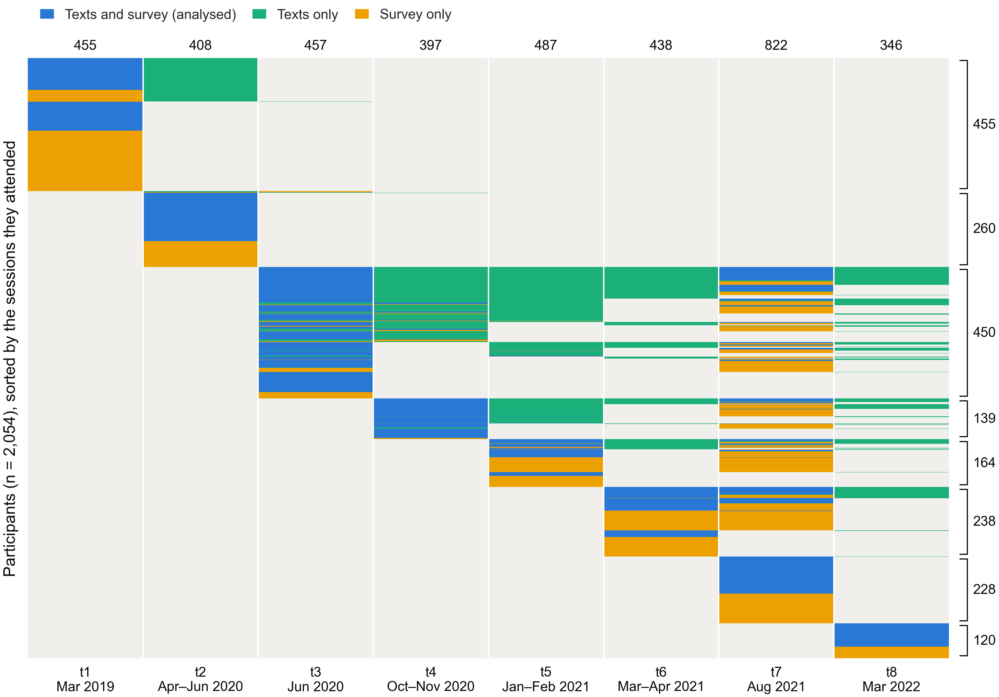

In [6]:
from cosowell_language.config import FEATURES_DIR
from cosowell_language.data_overview import (data_kinds_by_session, data_per_person_and_session, read_word_counts,
                                             retention_between_sessions, session_dates)
from cosowell_language.plots.data_overview_figure import draw_data_overview_figure

retention = retention_between_sessions(writers)
data_kinds = data_kinds_by_session(read_word_counts(FEATURES_DIR), survey_records)
display(retention, data_kinds)
draw_data_overview_figure(data_per_person_and_session(writers, survey_records), session_dates(), OUT / "fig0.png")
show("fig0.png", 820)

## 1b. Survey scores (questionnaire only, no test)

Each pair of scores over all records with a mixed model z(a) ~ z(b) + session + (1 | person), as people
answered at several sessions; then Pearson r within each session (cross-sectional). Benjamini–Hochberg q.

,count,mean,std,min,25%,50%,75%,max
loneliness,2608.0,4.49,1.85,3.00,3.00,4.00,6.00,9.00
isolation_index,2621.0,-0.00,0.57,-2.50,-0.38,-0.04,0.34,2.30
support_quality,2619.0,-0.00,0.76,-2.69,-0.32,0.25,0.56,0.97
health,2618.0,2.85,0.76,1.00,2.00,3.00,3.00,4.00
well_being_score,923.0,39.28,6.74,13.00,36.00,41.00,44.00,49.00
expressive_suppression,923.0,3.45,1.29,1.00,2.50,3.50,4.50,7.00
cognitive_reappraisal,923.0,5.16,1.11,1.00,4.50,5.17,6.00,7.00
age,2621.0,62.84,5.63,55.00,58.00,62.00,67.00,84.00
years_education,2599.0,16.30,3.29,0.00,14.00,16.00,18.00,30.00
female,2613.0,0.63,0.48,0.00,0.00,1.00,1.00,1.00


,score_a,score_b,scope,estimate,p,n_records,n_people,q
0,loneliness,isolation_index,all,0.274,0.000,2608,2041,0.000
1,loneliness,support_quality,all,-0.326,0.000,2607,2040,0.000
2,loneliness,health,all,-0.221,0.000,2605,2038,0.000
3,loneliness,well_being_score,all,-0.565,0.000,923,923,0.000
4,loneliness,expressive_suppression,all,0.156,0.000,923,923,0.000
5,loneliness,cognitive_reappraisal,all,-0.195,0.000,923,923,0.000
6,loneliness,age,all,-0.082,0.000,2608,2041,0.000
7,loneliness,years_education,all,0.002,0.913,2587,2023,0.933
8,loneliness,female,all,0.052,0.017,2600,2036,0.026
9,isolation_index,support_quality,all,-0.426,0.000,2619,2052,0.000


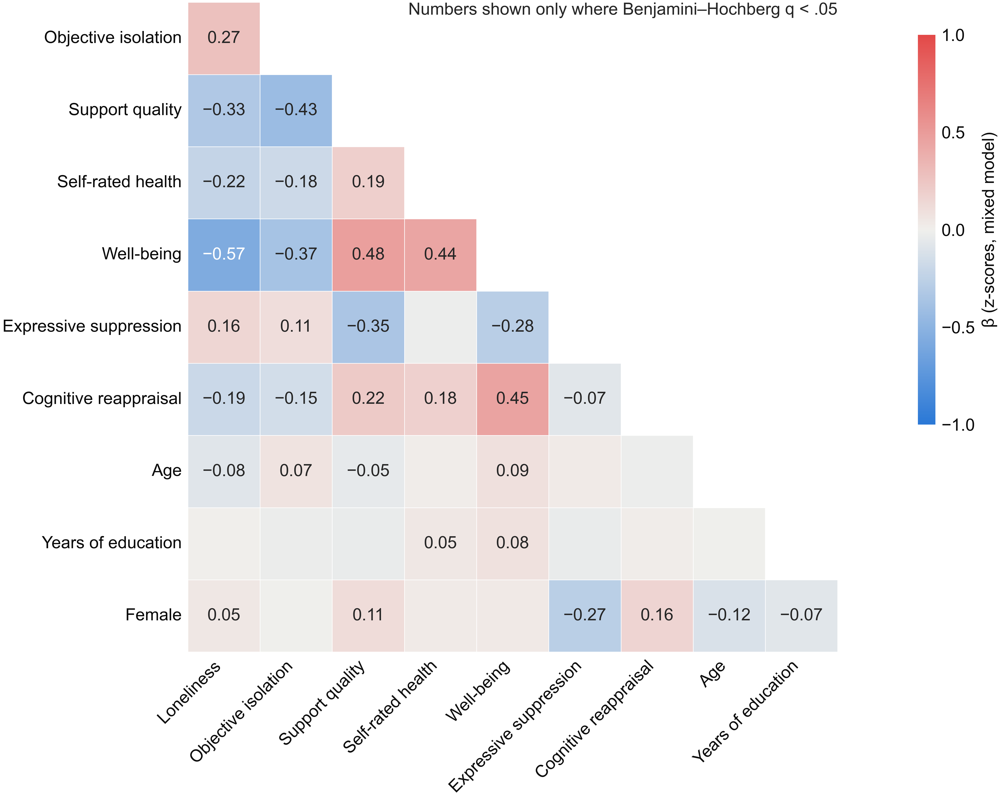

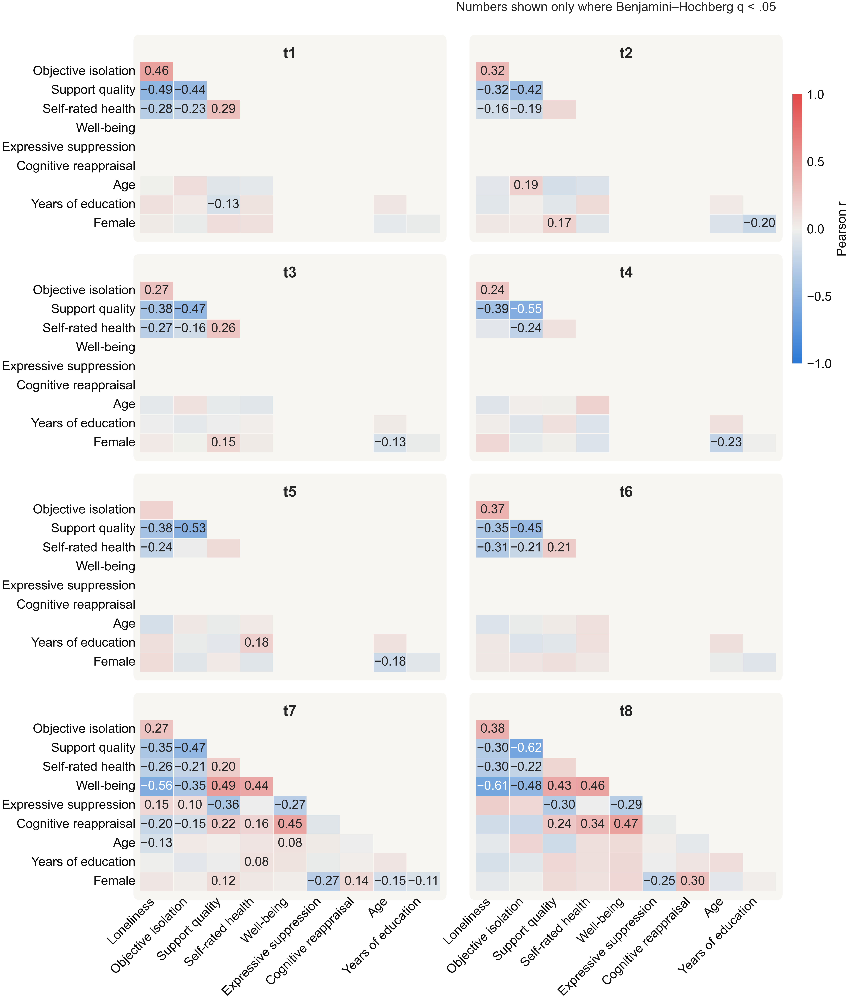

In [7]:
from cosowell_language.plots.survey_exploration_figures import (draw_loneliness_vs_isolation_figure,
                                                               draw_mixed_model_figure,
                                                               draw_session_correlation_figure)
from cosowell_language.survey.survey_exploration import (SCORES_USED, correlations_at_each_session,
                                                         loneliness_and_isolation, mixed_model_across_sessions,
                                                         survey_scores_used)

survey_scores = survey_scores_used(load_survey())
display(survey_scores[list(SCORES_USED)].describe().T.round(2))

over_all_sessions = mixed_model_across_sessions(survey_scores)
display(over_all_sessions.round(3))
draw_mixed_model_figure(over_all_sessions, SCORES_USED, OUT / "figS2a.png")
show("figS2a.png", 820)

at_each_session = correlations_at_each_session(survey_scores)
draw_session_correlation_figure(at_each_session, SCORES_USED, OUT / "figS2b.png")
show("figS2b.png", 1000)

score_associations = pd.concat([at_each_session, over_all_sessions], ignore_index=True)

**Loneliness vs objective isolation.** Loneliness is jittered vertically; the line is the mean per tenth of
isolation; the 95% CI resamples people.

,value
spearman_rho,0.2960
ci_low,0.2563
ci_high,0.3370
p,0.0000
n_records,2608.0000
n_people,2041.0000


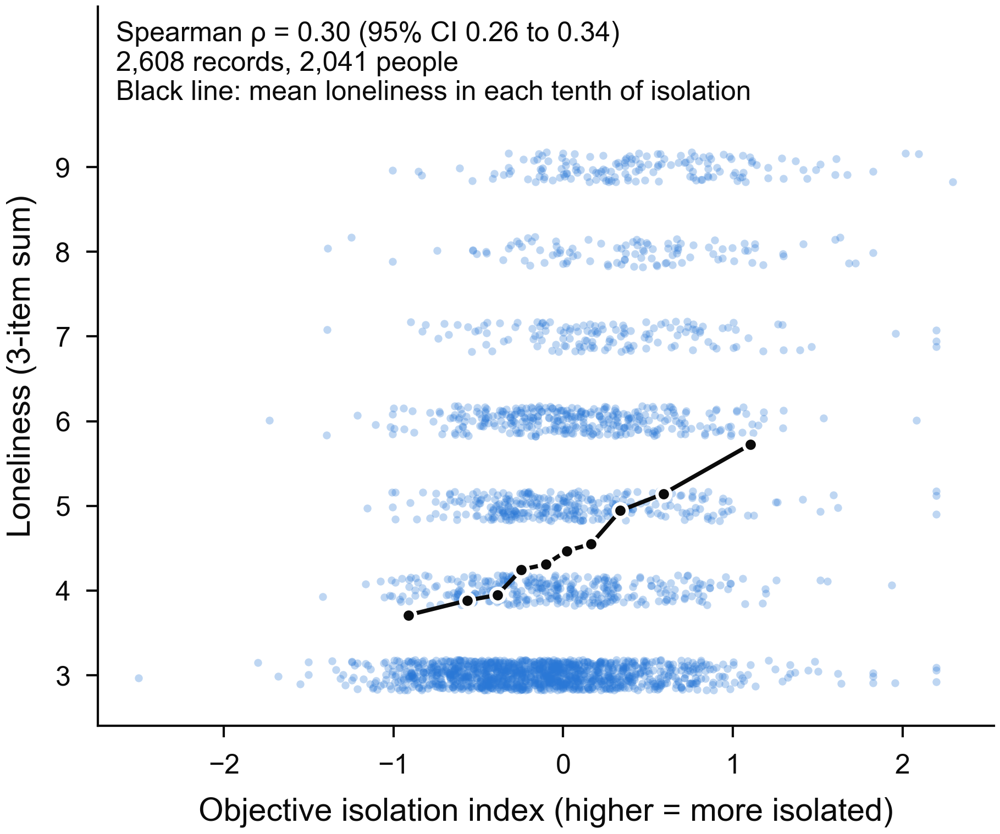

In [8]:
loneliness_isolation = loneliness_and_isolation(survey_scores)
display(loneliness_isolation.round(4).to_frame("value"))
draw_loneliness_vs_isolation_figure(survey_scores, loneliness_isolation, OUT / "figS3.png")
show("figS3.png", 460)

## 2. Metrics

Metrics per narrative are precomputed in `results/features/`. Kept if present in ≥ 80% of texts, non-zero in
≥ 10% and with > 5 distinct values; rank-normal transformed within text type. Survey scores are z-scored.

In [9]:
if CORPUS_PATH.exists():  # metrics of three narratives, text not shown
    from cosowell_language.data_loading import load_narratives
    from cosowell_language.metrics.all_language_metrics import measure_language

    demo = measure_language(load_narratives(CORPUS_PATH, ["yesterday"]).head(3), "yesterday")
    display(demo[["n_words", "fpp_singular_rate", "fpp_plural_rate", "n_relationships_named",
                  "sickness_pain_rate", "vader_compound"]].round(2))

,n_words,fpp_singular_rate,fpp_plural_rate,n_relationships_named,sickness_pain_rate,vader_compound
0,100,11.00,0.00,2,0.00,0.07
1,212,5.19,0.00,1,0.47,-0.04
2,319,9.09,0.63,0,0.31,-0.03


In [10]:
from cosowell_language.stats.analysis_data import load_analysis_data
from cosowell_language.stats.hit_counts_and_sample import sample_summary

data = load_analysis_data(NARRATIVE_TYPES)
text_metrics, features, used_metrics = data["text_metrics"], data["features"], data["used_metrics"]
session_scores, scored_texts = data["session_scores"], data["scored_texts"]
print(len(features), "metrics; per text type:", used_metrics.sum().to_dict())
sample_summary(session_scores, scored_texts).round(3).to_frame("value")

294 metrics; per text type: {'cookie': 242, 'past': 186, 'yesterday': 163, 'future': 147}


,value
sessions,1437.000
participants,1264.000
participants_two_sessions,173.000
narratives,5695.000
spearman_loneliness_isolation,0.298
sessions_with_loneliness,1433.000
sessions_with_isolation_index,1437.000
sessions_with_health,1435.000


## 3. All research-question tests

One regression per metric, research question and text type (OLS, standard errors clustered by person):

`metric ~ survey term(s) + age + years_education + health + female + covid_phase + log_n_words`

`female`: 1 = female, 0 = male; `covid_phase`: 1 = session after 13 March 2020; `log_n_words`: log word count.
All are z-scored. `log_n_words` is left out for length metrics; pooled
models add text-type indicators. `robust_hits` counts tests, so one metric can count several times.

In [11]:
from cosowell_language.config import FINDINGS
from cosowell_language.stats.metric_regression_model import covariates_for

# The exact right-hand side of each model, as the code builds it.
for name, spec in FINDINGS.items():
    terms = spec["terms"]
    covariates = covariates_for("metric", terms, spec.get("adjust", ()))
    print(f"{labels.HYPOTHESIS[name]:<6} metric ~ {' + '.join(terms + covariates)}")

RQ1    metric ~ isolation_index + age + years_education + health + female + covid_phase + log_n_words
RQ2    metric ~ loneliness + age + years_education + health + female + covid_phase + log_n_words
RQ1–2  metric ~ loneliness + isolation_index + age + years_education + health + female + covid_phase + log_n_words


In [12]:
from cosowell_language.stats.metric_regression_model import scopes
from cosowell_language.stats.hit_replication import replicate_fdr_hits
from cosowell_language.stats.hypothesis_tests import run_hypothesis_tests
from cosowell_language.stats.hit_counts_and_sample import count_tests_and_hits

types = NARRATIVE_TYPES
all_tests = run_hypothesis_tests(scored_texts, features, types)
hits = replicate_fdr_hits(all_tests, scored_texts, text_metrics, used_metrics, types)
test_counts = count_tests_and_hits(all_tests, hits)
test_counts.insert(0, "question", test_counts["finding"].map(labels.HYPOTHESIS))
test_counts[["question", "term", "tests", "nominal_p05", "fdr_hits", "holm_hits", "robust_hits",
             "robust_hits_all_findings"]]

,question,term,tests,nominal_p05,fdr_hits,holm_hits,robust_hits,robust_hits_all_findings
0,RQ1,isolation_index,912,154,57,31,35,34
1,RQ2,loneliness,912,100,10,1,5,5
2,RQ1–2,loneliness,912,69,4,0,0,0
3,RQ1–2,isolation_index,912,145,40,24,28,28


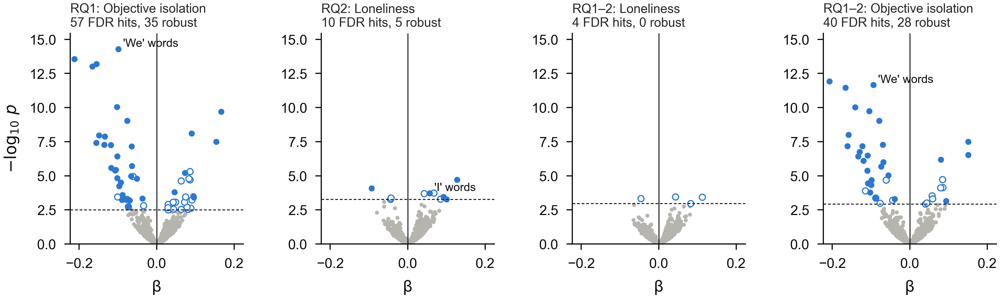

In [13]:
from cosowell_language.plots.volcano_figure import draw_volcano_figure

draw_volcano_figure(all_tests, hits, OUT / "fig1.png")
show("fig1.png", 820)

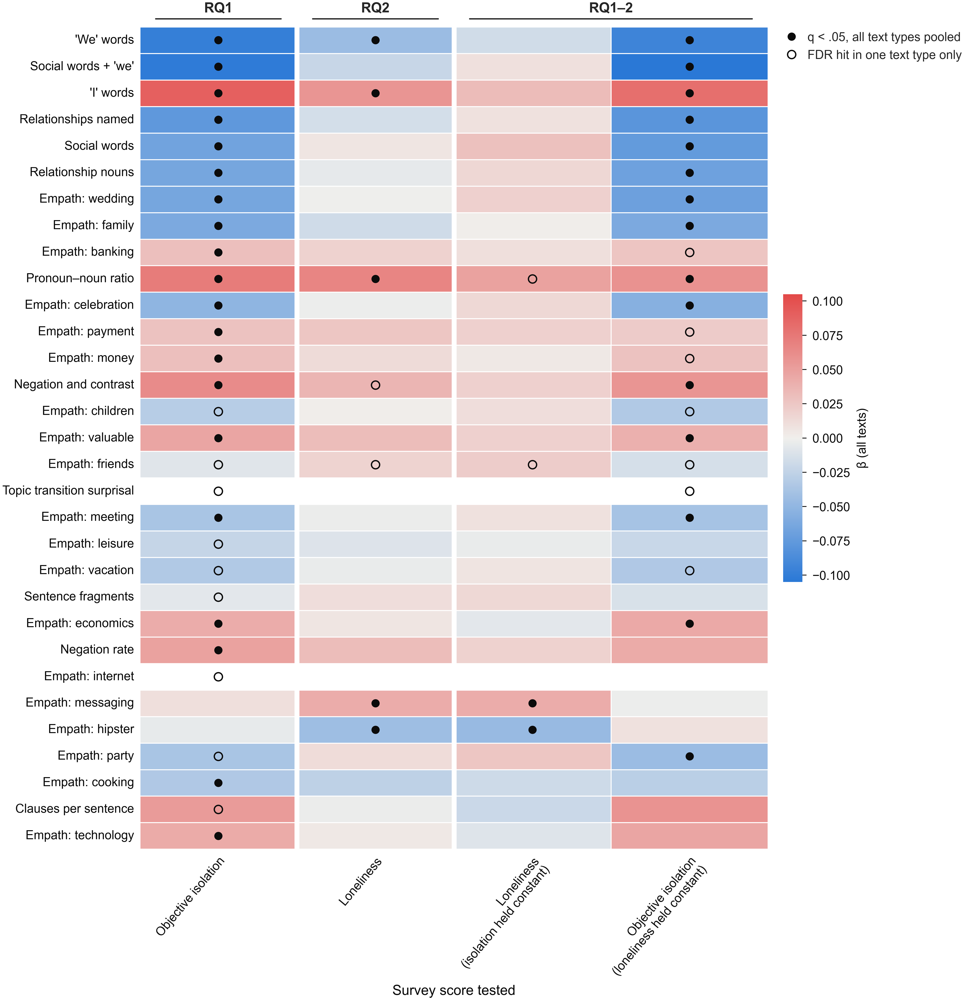

In [14]:
from cosowell_language.plots.fdr_hit_heatmap_figure import draw_fdr_hit_heatmap

draw_fdr_hit_heatmap(all_tests, hits, "pooled", OUT / "figS1.png")
show("figS1.png", 820)

In [15]:
FINDING = {code: finding for finding, code in labels.HYPOTHESIS.items()}     # 'RQ1' -> 'RQ1 isolation'


def robust_tests_of(question, term=None):
    robust = hits[hits["finding"].eq(FINDING[question]) & hits["verdict"].eq("robust")]
    return robust[robust["term"].eq(term)] if term else robust


def strongest_markers_of(question, term, scope="pooled", n=10):
    """Robust markers of a survey variable, strongest first."""
    found = robust_tests_of(question, term)
    found = found[found["scope"].eq(scope)] if scope else found
    columns = ["feature", "scope", "beta", "ci_low", "ci_high", "q", "p_holm", "types_same_sign"]
    found = found.sort_values("q").head(n)[columns]
    return found.assign(feature=found["feature"].map(labels.metric)).round(3)


def number_of_markers(question, term=None):
    """Different metrics with at least one robust test (a metric can pass in several texts)."""
    return robust_tests_of(question, term)["feature"].nunique()


def test_counts_of(question):
    columns = ["term", "tests", "nominal_p05", "fdr_hits", "robust_hits"]
    return test_counts[test_counts["question"].eq(question)][columns].to_string(index=False)

**Markers by group.** Up to three markers: box plots of the raw values with Cliff's δ. More than three: a PCA of
the markers (normal scores), every session coloured by its group, and the group means with 95% CIs.

In [16]:
from cosowell_language.plots.marker_figures import draw_markers_of_question
from cosowell_language.plots.figure_style import BLUE_RAMP, ORANGE_RAMP
from cosowell_language.stats.box_plot_data import MARKER_GROUPINGS, marker_values_and_effect_sizes

marker_sessions, marker_effects = marker_values_and_effect_sizes(data["raw"], session_scores, hits)


def draw_markers_of(question, term, colors=BLUE_RAMP[1:], width=820):
    finding = FINDING[question]
    of_question = marker_effects[marker_effects["finding"].eq(finding) & marker_effects["term"].eq(term)]
    group, xlabel, levels = MARKER_GROUPINGS[(finding, term)]
    file_name = f"markers_{question}_{term}.png"
    draw_markers_of_question(marker_sessions, of_question, group, xlabel, levels, colors, OUT / file_name)
    show(file_name, width)

## 4. RQ1. Objective isolation

**Test.** Metric ~ isolation + covariates.

In [17]:
print(test_counts_of("RQ1"))
print("Marker metrics:", number_of_markers("RQ1", "isolation_index"))
strongest_markers_of("RQ1", "isolation_index")

           term  tests  nominal_p05  fdr_hits  robust_hits
isolation_index    912          154        57           35
Marker metrics: 18


,feature,scope,beta,ci_low,ci_high,q,p_holm,types_same_sign
22,'We' words,pooled,-0.099,-0.123,-0.074,0.000,0.000,3/4
26,Social words + 'we',pooled,-0.103,-0.133,-0.072,0.000,0.000,3/4
28,Relationships named,pooled,-0.076,-0.101,-0.052,0.000,0.000,4/4
29,'I' words,pooled,0.090,0.059,0.120,0.000,0.000,3/4
36,Empath: wedding,pooled,-0.065,-0.088,-0.041,0.000,0.000,4/4
38,Relationship nouns,pooled,-0.064,-0.091,-0.038,0.000,0.002,3/4
42,Pronoun–noun ratio,pooled,0.073,0.041,0.105,0.000,0.005,4/4
43,Social words,pooled,-0.067,-0.096,-0.037,0.000,0.009,4/4
45,Empath: celebration,pooled,-0.051,-0.074,-0.028,0.001,0.014,4/4
48,Empath: valuable,pooled,0.046,0.022,0.070,0.004,0.136,3/3


,grouping,metric,median_low,median_high,cliffs_delta,delta_ci_low,delta_ci_high,delta_size
0,isolation_group,fpp_plural_rate,1.376,0.467,-0.308,-0.380,-0.230,small
1,isolation_group,fpp_singular_rate,6.909,8.275,0.255,0.185,0.333,small
2,isolation_group,social_plus_we_rate,6.314,4.515,-0.289,-0.361,-0.220,small
3,loneliness_group,fpp_plural_rate,1.210,0.694,-0.170,-0.245,-0.097,small
4,loneliness_group,fpp_singular_rate,7.317,8.053,0.130,0.055,0.202,negligible
5,loneliness_group,social_plus_we_rate,5.871,4.818,-0.130,-0.208,-0.054,negligible


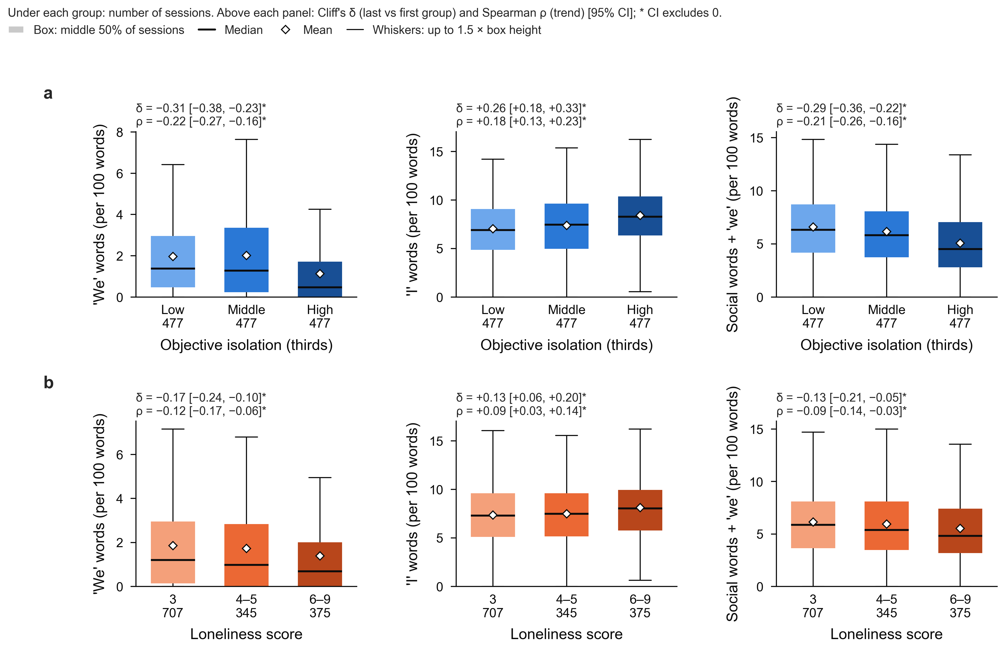

In [18]:
from cosowell_language.plots.box_plot_figure import draw_box_plots
from cosowell_language.plots.figure_style import BLUE_RAMP, DOUBLE_COLUMN, ORANGE_RAMP
from cosowell_language.plots.text_type_forest_figure import draw_text_type_forest_figure
from cosowell_language.stats.box_plot_data import SOCIAL_METRICS, box_plot_data_and_effect_sizes
from cosowell_language.stats.box_plot_effect_sizes import effect_label

box_plot_sessions, box_plot_effects = box_plot_data_and_effect_sizes(data["raw"], session_scores)
effect_labels = {(r.grouping, r.metric): effect_label(r) for r in box_plot_effects.itertuples()}
effect_columns = ["grouping", "metric", "median_low", "median_high", "cliffs_delta", "delta_ci_low",
                  "delta_ci_high", "delta_size"]
display(box_plot_effects[effect_columns].round(3))
draw_box_plots(box_plot_sessions, SOCIAL_METRICS,
               [("isolation_group", "Objective isolation (thirds)", ["Low", "Middle", "High"], BLUE_RAMP[1:]),
                ("loneliness_group", "Loneliness score", ["3", "4–5", "6–9"], ORANGE_RAMP[1:])],
               OUT / "fig3.png", DOUBLE_COLUMN, effect_labels)
show("fig3.png", 820)

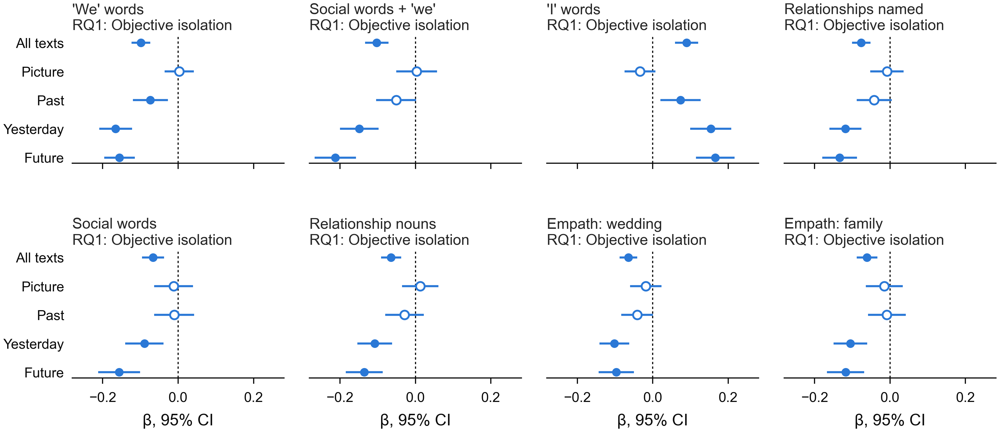

In [19]:
draw_text_type_forest_figure(hits, all_tests, scopes(types), OUT / "fig4.png", max_panels=8,
                             finding="RQ1 isolation", term="isolation_index")
show("fig4.png", 820)

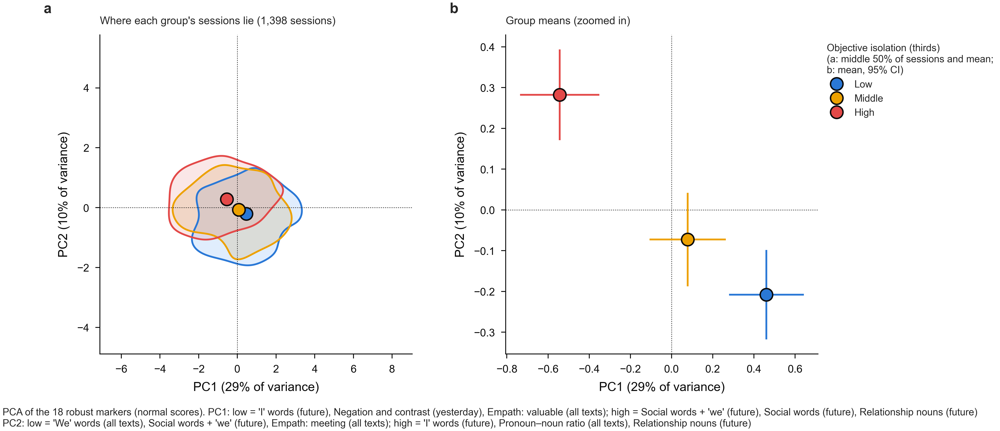

In [20]:
draw_markers_of("RQ1", "isolation_index")

**Answer RQ1: yes.**

## 5. RQ2. Loneliness

**Test.** Metric ~ loneliness + covariates. **Follow-up (RQ1–2).** Metric ~ loneliness + isolation + covariates,
because lonely people are also more isolated.

In [21]:
print(test_counts_of("RQ2"))
print("Marker metrics:", number_of_markers("RQ2", "loneliness"))
display(strongest_markers_of("RQ2", "loneliness", scope=None))
print(test_counts_of("RQ1–2"))
print("Marker metrics with both in the model, loneliness:", number_of_markers("RQ1–2", "loneliness"),
      "| isolation:", number_of_markers("RQ1–2", "isolation_index"))

      term  tests  nominal_p05  fdr_hits  robust_hits
loneliness    912          100        10            5
Marker metrics: 4


,feature,scope,beta,ci_low,ci_high,q,p_holm,types_same_sign
106,Pronoun–noun ratio,future,0.127,0.069,0.185,0.018,0.018,4/4
107,'I' words,pooled,0.057,0.027,0.086,0.037,0.172,3/4
108,'We' words,future,-0.093,-0.140,-0.047,0.037,0.075,4/4
109,'I' words,future,0.100,0.044,0.157,0.048,0.475,3/4
110,Negation and contrast,yesterday,0.092,0.042,0.143,0.048,0.322,4/4


           term  tests  nominal_p05  fdr_hits  robust_hits
     loneliness    912           69         4            0
isolation_index    912          145        40           28
Marker metrics with both in the model, loneliness: 0 | isolation: 12


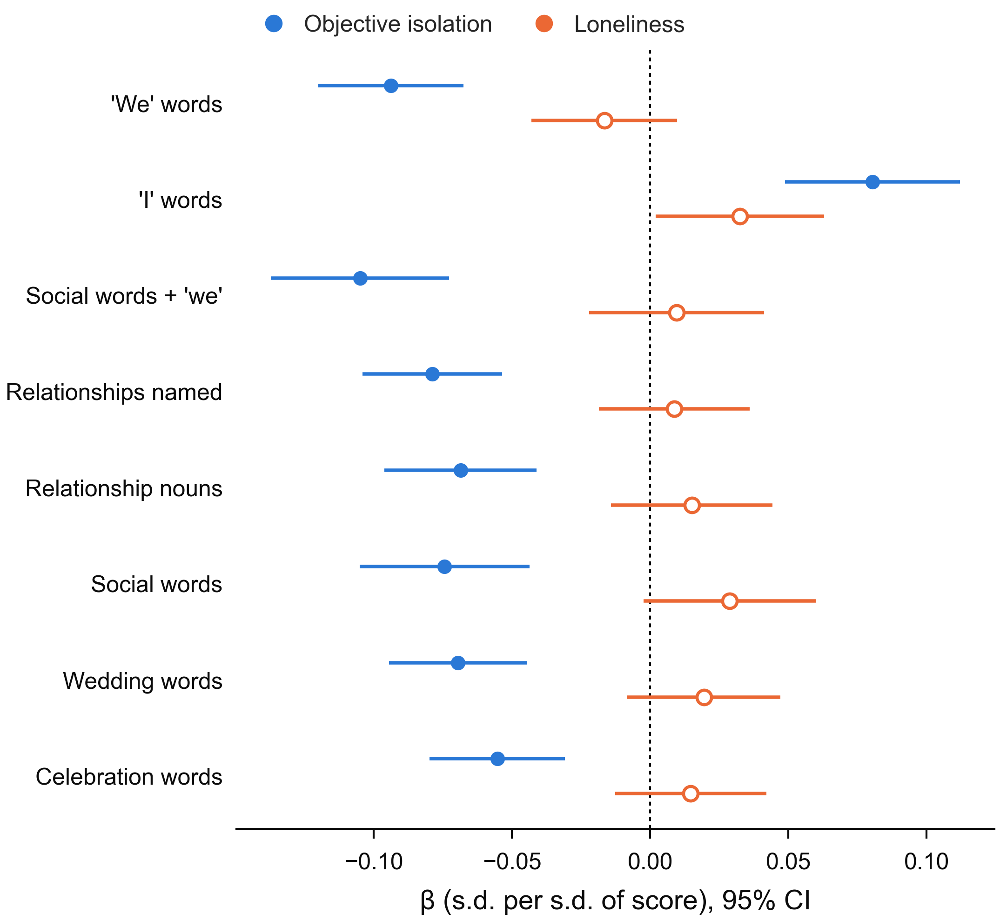

In [22]:
from cosowell_language.plots.beta_comparison_figures import draw_isolation_vs_loneliness_figure
from cosowell_language.plots.figure_labels import ISOLATION_MARKERS

draw_isolation_vs_loneliness_figure(all_tests, ISOLATION_MARKERS, OUT / "fig2.png")
show("fig2.png", 420)

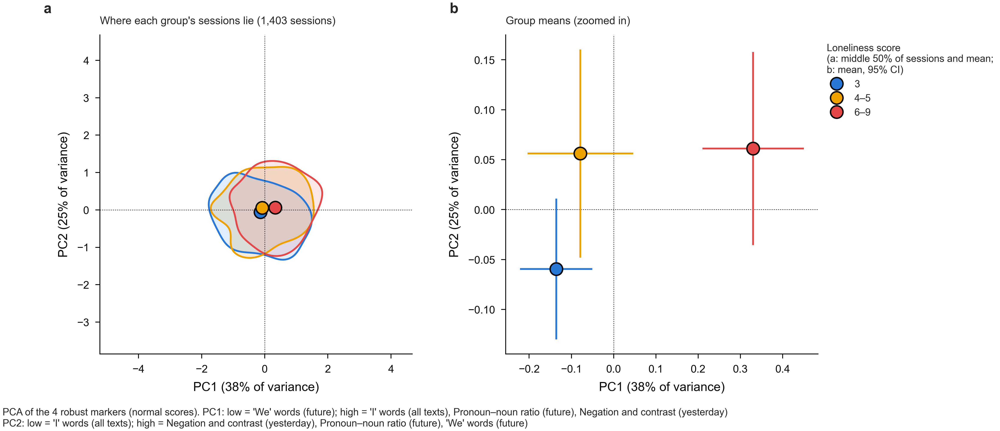

In [23]:
draw_markers_of("RQ2", "loneliness", ORANGE_RAMP[1:])

**Answer RQ2: weakly, and not beyond isolation.**

## 6. Picture task alone

The RQ1, RQ2 and RQ1–2 tests on the picture description only.

In [24]:
picture_data = load_analysis_data(["cookie"])
picture_tests = run_hypothesis_tests(picture_data["scored_texts"], picture_data["features"], ["cookie"])
picture_hits = replicate_fdr_hits(picture_tests, picture_data["scored_texts"], picture_data["text_metrics"],
                                  picture_data["used_metrics"], ["cookie"])
print(len(picture_data["features"]), "metrics;", len(picture_hits), "FDR hits for any research question; smallest q:",
      round(picture_tests["q"].min(), 3))

242 metrics; 0 FDR hits for any research question; smallest q: 0.06


## 7. Machine-learning classifiers per text type

```
SET-UP ----------------------------------------------------------------------------------------------------
for each label                lonely (loneliness 6–9) | isolated (top third of the isolation index)
  for each text type          picture | past | yesterday | future
    texts                     every text of the type whose writer has the label at that session
    metrics                   earlier FDR hits for loneliness or isolation (RQ1, RQ2, RQ1–2), if used in this type
    5 test folds              people split once, the same in every run; a person's texts stay in one fold

OUTER LOOP: testing ---------------------------------------------------------------------------------------
    for each test fold        test people = this fold; training people = the other 4
      for each classifier     logistic, lasso, elastic-net, SVM, random forest, gradient boosting, k-NN, naive Bayes
        tune                  INNER LOOP below, on the training people only
        refit                 the best settings, all steps, on all 4 training folds
        predict               each test text: class and probability (test texts never resampled)
        score                 balanced accuracy, ROC AUC
    summary                   mean ± SD over the 5 test folds

INNER LOOP: tuning, training people only ------------------------------------------------------------------
        split                 training people into 5 inner folds
        for each setting      every combination of the classifier's hyperparameter grid
          for each inner fold   fit on 4 inner folds, ROC AUC on the 5th:
            impute                median
            z-score
            select metrics        F-test between the two classes, BH q < .05 (at least 5 kept)
            SMOTE                 synthetic texts until both classes are equally large
            fit classifier
        best settings         highest mean inner ROC AUC

RESULTS: Figs. 5–6 ----------------------------------------------------------------------------------------
ranking                       classifiers ordered by inner AUC (training folds only), averaged over labels,
                              text types and test folds; the top 4 are drawn
Fig. 5                        bars: balanced accuracy and ROC AUC per text type, mean ± SD over the test folds
top model                     the first of the ranking; the ONE model used from here on (Fig. 6 and both pilots)
Fig. 6                        ROC curves of the top model in every label × text type: mean of the fold curves ± SD
```

The candidate metrics were found with all people, so the scores are somewhat optimistic.

loneliness / cookie: 1418 texts x 25 metrics, 26% positive


loneliness / past: 1431 texts x 28 metrics, 26% positive


loneliness / yesterday: 1418 texts x 29 metrics, 26% positive


loneliness / future: 1412 texts x 29 metrics, 26% positive


isolation_index / cookie: 1422 texts x 25 metrics, 33% positive


isolation_index / past: 1435 texts x 28 metrics, 33% positive


isolation_index / yesterday: 1422 texts x 29 metrics, 33% positive


isolation_index / future: 1416 texts x 29 metrics, 33% positive


,model,mean_inner_cv_roc_auc,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_roc_auc,rank,shown_in_figure
0,Lasso logistic,0.565,0.556,0.548,0.563,1,True
1,Elastic-net logistic,0.564,0.551,0.554,0.567,2,True
2,Logistic regression,0.563,0.552,0.552,0.568,3,True
3,SVM (RBF),0.563,0.542,0.550,0.552,4,True
4,Naive Bayes,0.553,0.534,0.546,0.561,5,False
5,Random forest,0.552,0.564,0.535,0.554,6,False
6,Gradient boosting,0.547,0.547,0.531,0.550,7,False
7,k-nearest neighbours,0.545,0.529,0.533,0.547,8,False


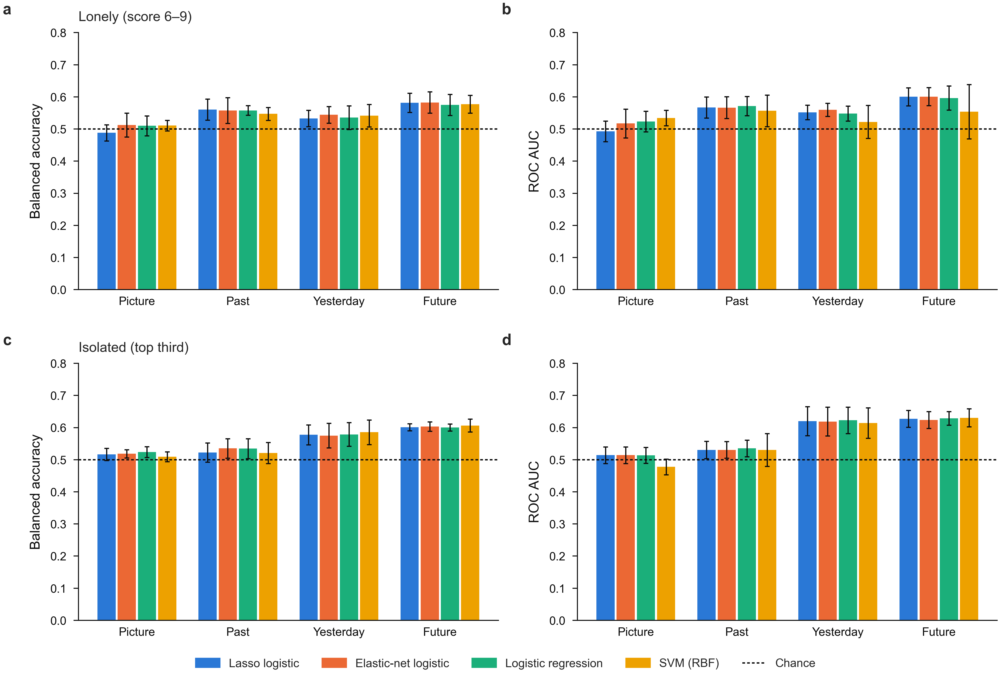

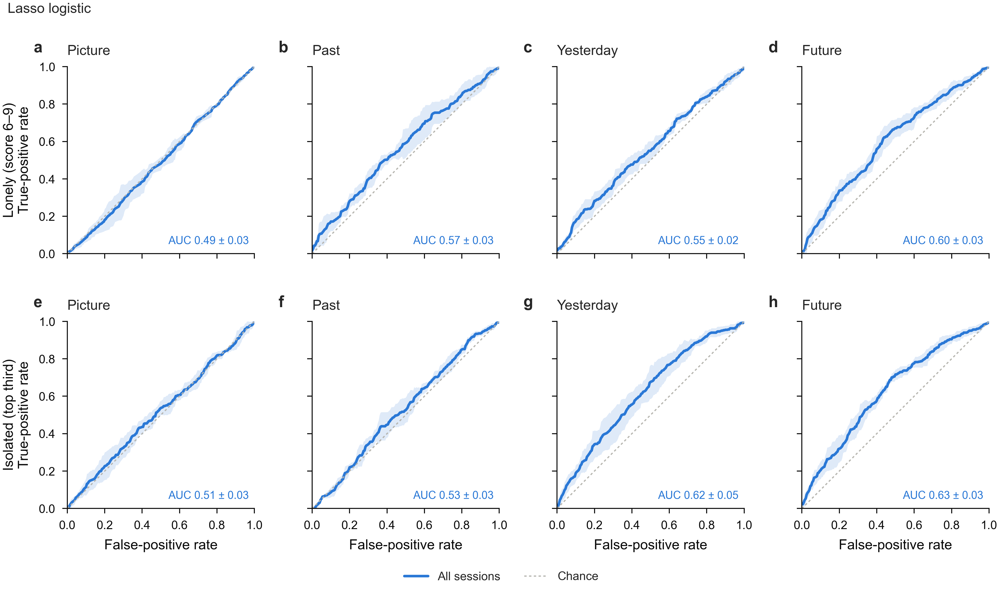

In [25]:
from cosowell_language.plots.model_comparison_figure import draw_model_comparison_figure, draw_roc_curves_figure
from cosowell_language.stats.model_comparison_per_text import TARGETS, classify_per_text_type, rank_models, summarise_folds

classifier_folds, classifier_predictions = classify_per_text_type(data["scored_texts"], data["session_scores"],
                                                                  data["used_metrics"], hits)
classifier_summary = summarise_folds(classifier_folds)
classifier_ranking = rank_models(classifier_folds)
top_model = classifier_ranking.loc[0, "model"]     # the one model used for the ROC curves and both pilots
display(classifier_ranking.round(3))
draw_model_comparison_figure(classifier_summary, classifier_ranking, TARGETS, OUT / "fig5.png")
draw_roc_curves_figure(classifier_predictions, top_model, TARGETS, OUT / "fig6.png")
show("fig5.png", 720)
show("fig6.png", 720)

**Top model, a closer look**

Classification report: precision, recall and F1 per class from the out-of-fold predictions (mean ± SD over the
test folds; support summed over them). Recall of the positive class = sensitivity, of the negative class =
specificity.

In [26]:
from cosowell_language.stats.classifier_explanation import (classification_report_table, confusion_matrices,
                                                          metric_importance)

classification_report = classification_report_table(classifier_predictions, top_model)
display(classification_report.round(3))
confusion_matrices(classifier_predictions, top_model)

,target,ntype,class,precision_mean,precision_std,recall_mean,recall_std,f1-score_mean,f1-score_std,support
0,loneliness,cookie,Not lonely,0.729,0.035,0.785,0.295,0.734,0.160,1047
1,loneliness,cookie,Lonely,0.097,0.136,0.191,0.262,0.128,0.178,371
2,loneliness,cookie,macro avg,0.413,0.064,0.488,0.025,0.431,0.029,1418
3,loneliness,cookie,weighted avg,0.565,0.055,0.630,0.154,0.576,0.085,1418
4,loneliness,past,Not lonely,0.781,0.053,0.560,0.054,0.650,0.029,1055
5,loneliness,past,Lonely,0.312,0.046,0.561,0.090,0.396,0.031,376
6,loneliness,past,macro avg,0.546,0.023,0.561,0.033,0.523,0.026,1431
7,loneliness,past,weighted avg,0.661,0.051,0.557,0.028,0.583,0.023,1431
8,loneliness,yesterday,Not lonely,0.761,0.043,0.555,0.035,0.641,0.026,1046
9,loneliness,yesterday,Lonely,0.290,0.050,0.510,0.028,0.367,0.042,372


,target,ntype,true_negative,false_positive,false_negative,true_positive
0,loneliness,cookie,823,224,300,71
1,loneliness,past,589,466,168,208
2,loneliness,yesterday,580,466,183,189
3,loneliness,future,560,481,141,230
4,isolation_index,cookie,476,473,221,252
5,isolation_index,past,466,490,211,268
6,isolation_index,yesterday,491,459,171,301
7,isolation_index,future,501,442,156,317


**Metric importance.** The top model is tuned again on the training people of each outer fold (same folds and
seeds, so the same models); each metric is shuffled 20 times in the test fold, and the drop in ROC AUC is its
importance. Metrics with no effect in any fold are not drawn.

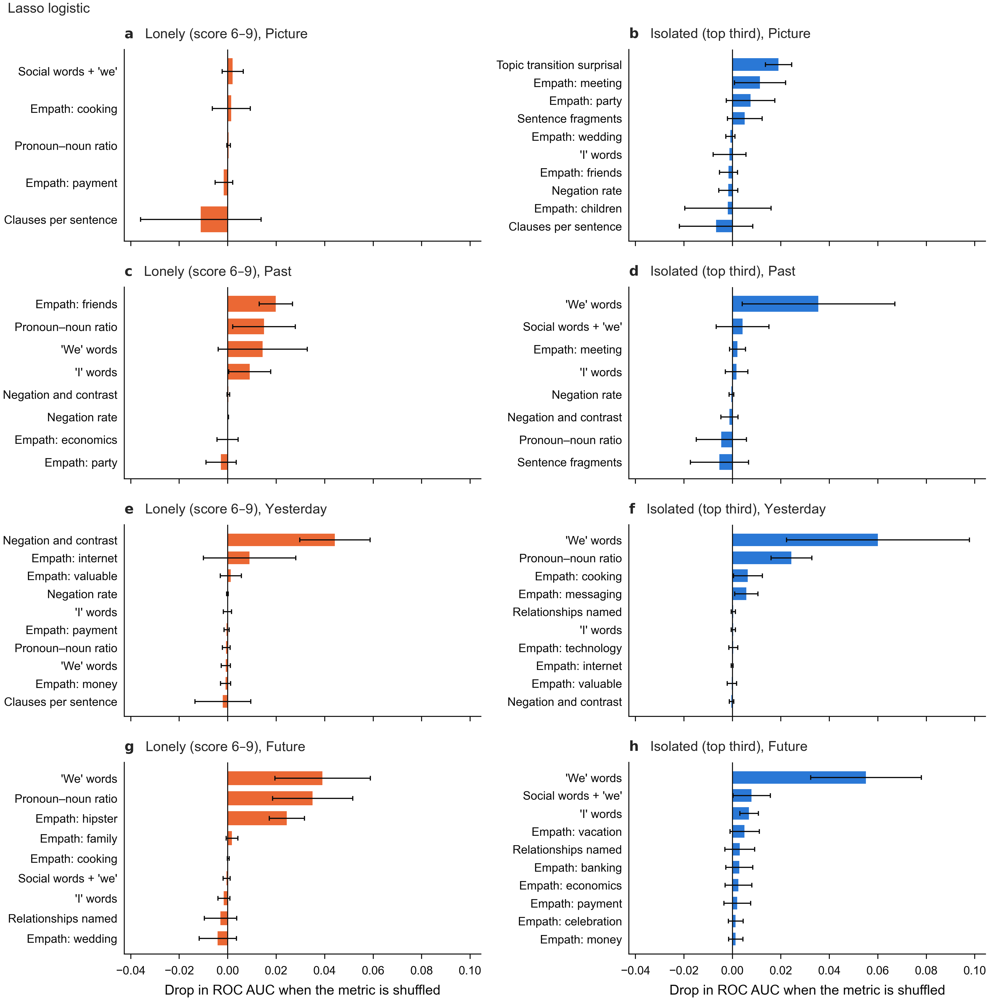

In [27]:
from cosowell_language.plots.classifier_explanation_figures import draw_metric_importance_figure

importance = metric_importance(data["scored_texts"], data["session_scores"], data["used_metrics"], hits, top_model)
draw_metric_importance_figure(importance, top_model, TARGETS, OUT / "figS6.png")
show("figS6.png", 820)

**Pilots: where loneliness and isolation part ways**

```
INPUT: no new fitting -------------------------------------------------------------------------------------
predictions                   the out-of-fold predictions above: each text predicted once, by a model that
                              never saw its writer
classifier                    the same top-ranked model as Fig. 6 (highest inner AUC)

GROUPS of sessions ----------------------------------------------------------------------------------------
label agreement               agree = lonely and isolated, or neither; disagree = only one of the two
distance from the line        MixedLM z(loneliness) ~ z(isolation) + C(session) + (1 | person), all sessions
                              residual = loneliness − fixed part (intercept, slope, session; no person intercept)
                              off the line = |residual| > 1 SD, on the line otherwise          (Fig. 8a)

SCORING ---------------------------------------------------------------------------------------------------
for each label × text type × group × test fold
  score                       balanced accuracy, ROC AUC of the texts in the group
summary                       mean ± SD over the test folds                      (Figs. 7a, 8b)
ROC curves                    per group, label and text type: mean of the fold curves ± SD  (Figs. 7b, 8c)
```

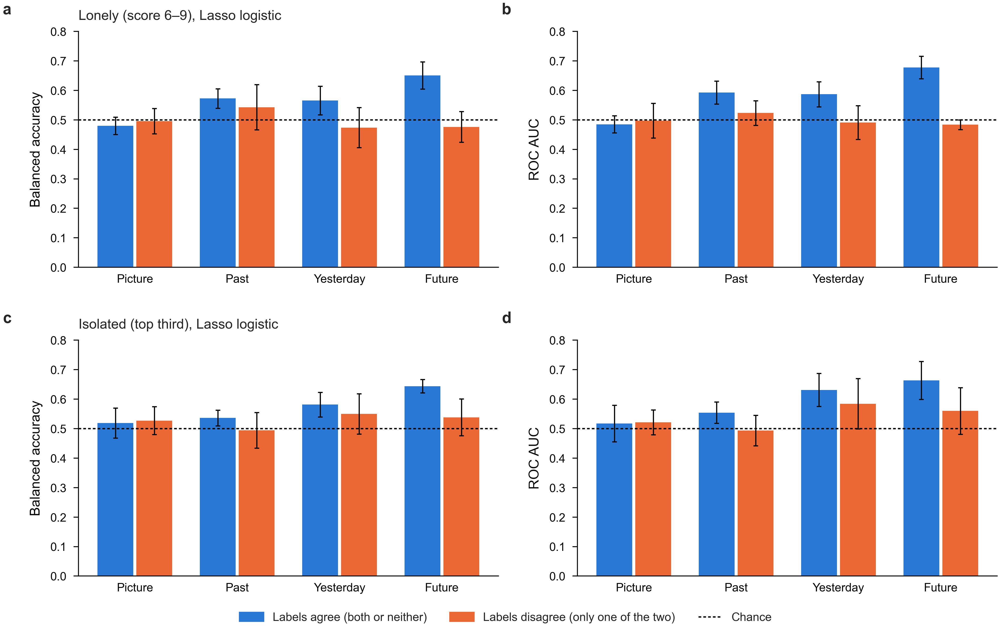

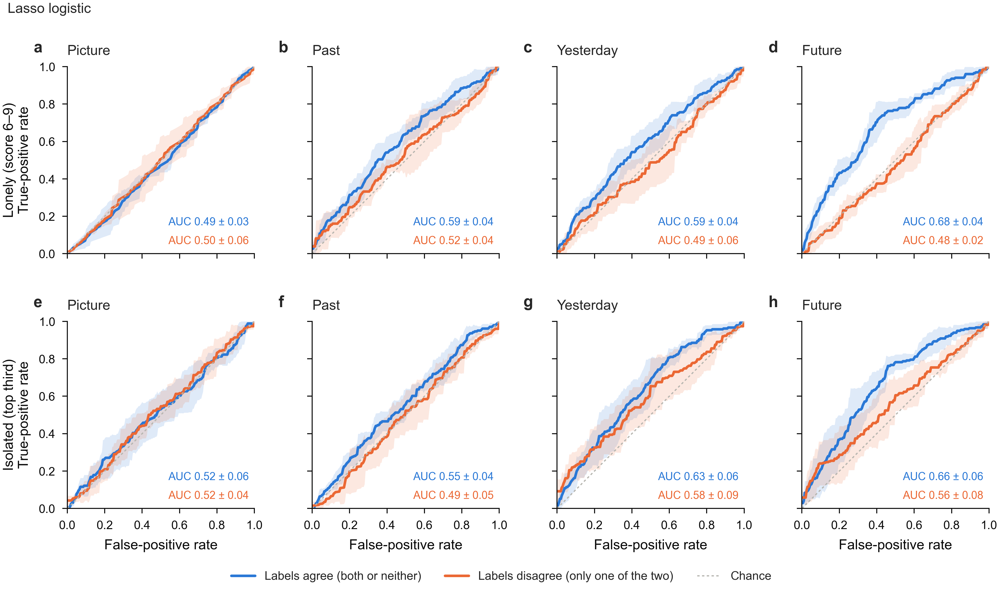

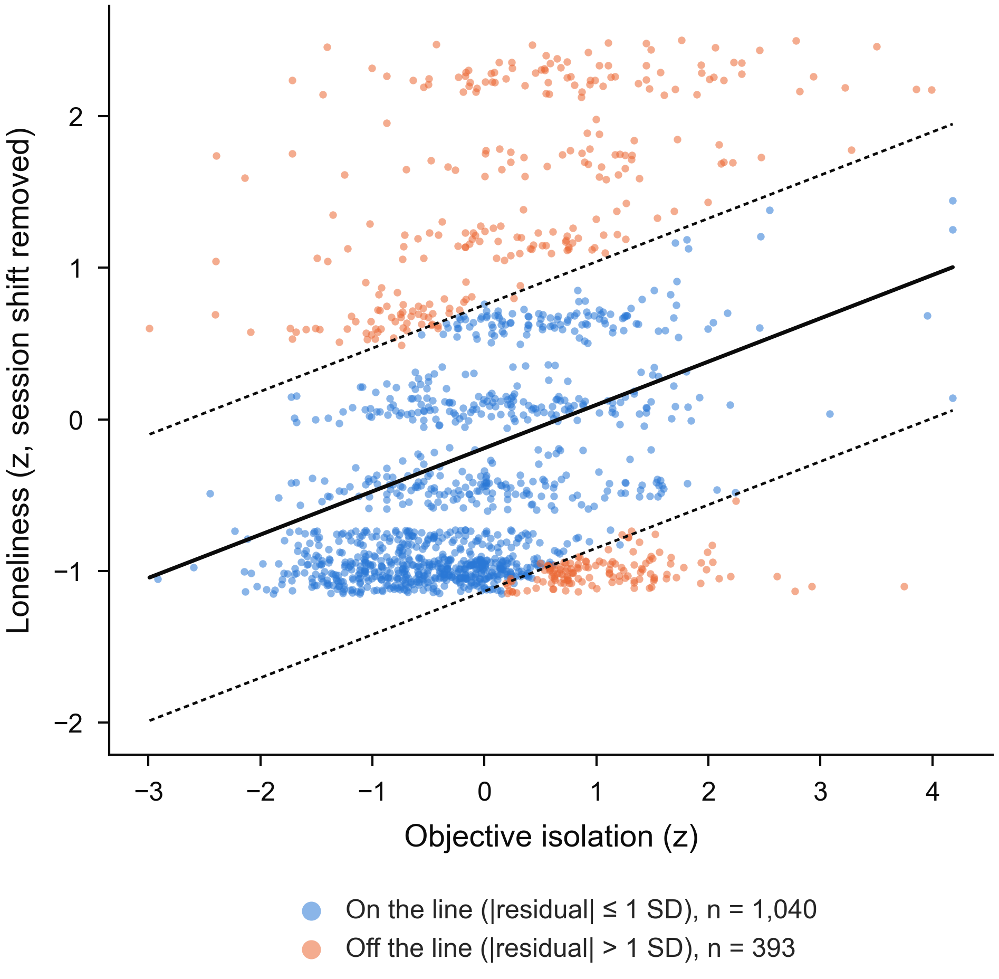

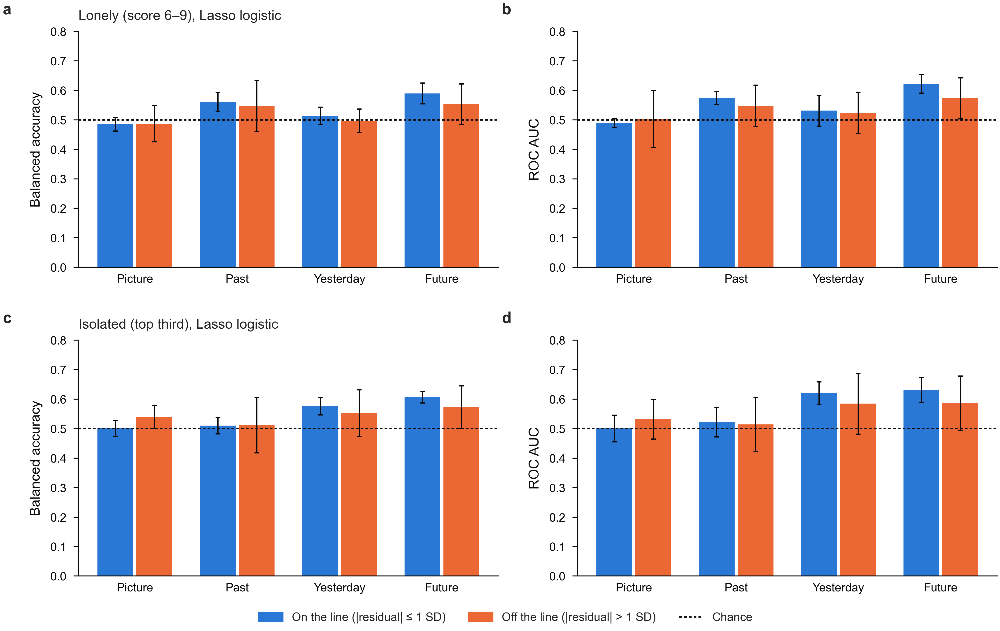

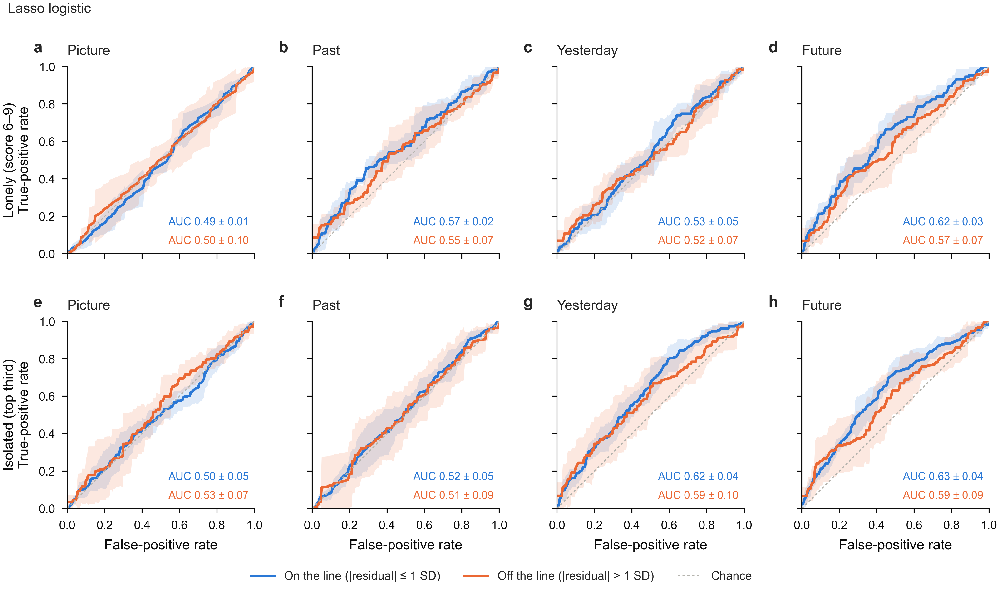

In [28]:
from cosowell_language.plots.model_comparison_figure import (draw_distance_from_line_groups_figure,
                                                            draw_roc_curves_figure, draw_scores_by_group_figure)
from cosowell_language.stats.model_comparison_per_text import (DISTANCE_FROM_LINE, LABEL_AGREEMENT,
                                                              distance_from_line_groups, label_agreement_groups,
                                                              scores_by_group)

agreement = label_agreement_groups(data["scored_texts"], data["session_scores"])
by_agreement = scores_by_group(classifier_predictions, agreement)
distance_from_line = distance_from_line_groups(data["session_scores"])
by_distance = scores_by_group(classifier_predictions, distance_from_line)
draw_scores_by_group_figure(by_agreement, top_model, LABEL_AGREEMENT, TARGETS, OUT / "fig7a.png")
draw_roc_curves_figure(classifier_predictions, top_model, TARGETS, OUT / "fig7b.png", agreement, LABEL_AGREEMENT)
draw_distance_from_line_groups_figure(distance_from_line, DISTANCE_FROM_LINE, OUT / "fig8a.png")
draw_scores_by_group_figure(by_distance, top_model, DISTANCE_FROM_LINE, TARGETS, OUT / "fig8b.png")
draw_roc_curves_figure(classifier_predictions, top_model, TARGETS, OUT / "fig8c.png", distance_from_line,
                       DISTANCE_FROM_LINE)
show("fig7a.png", 720)
show("fig7b.png", 720)
show("fig8a.png", 360)
show("fig8b.png", 720)
show("fig8c.png", 720)

## 8. Reproducibility check

Every number above must equal the saved results in `results/`.

In [29]:
def largest_difference(computed, saved, columns, keys):
    """Largest absolute difference between a table computed here and the saved one, matched on keys."""
    both = computed.merge(saved, on=keys, suffixes=("", "_saved"))
    assert len(both) == len(computed) == len(saved), (len(computed), len(saved), len(both))
    return max(float(np.nanmax(np.abs(both[c] - both[c + "_saved"]))) for c in columns)


def saved(path, **kwargs):
    return pd.read_csv(RESULTS_DIR / path, **kwargs)


test_keys = ["finding", "feature", "scope", "term"]
checks = {
    "survey score associations": largest_difference(
        score_associations, saved("survey_exploration/score_associations.csv"), ["estimate", "p", "q"],
        ["score_a", "score_b", "scope"]),
    "loneliness vs isolation (rho, CI)": float(np.max(np.abs(
        loneliness_isolation - saved("survey_exploration/loneliness_vs_isolation.csv", index_col=0)["value"]))),
    "research-question tests (beta, p, q, Holm)": largest_difference(
        all_tests, saved("all/screen.csv"), ["beta", "p", "q", "p_holm"], test_keys),
    "markers and replication": largest_difference(
        hits, saved("all/hits.csv"), ["beta", "beta_half_a", "p_half_b"], test_keys),
    "picture task alone": largest_difference(picture_tests, saved("cookie/screen.csv"), ["beta", "p", "q"], test_keys),
    "marker box-plot effect sizes": largest_difference(
        marker_effects, saved("all/marker_group_effect_sizes.csv"),
        ["cliffs_delta", "delta_ci_low", "spearman_rho"], ["finding", "term", "metric"]),
    "box-plot effect sizes": largest_difference(
        box_plot_effects, saved("all/group_effect_sizes.csv"),
        ["cliffs_delta", "delta_ci_low", "spearman_rho"], ["grouping", "metric"]),
    "classifiers (fold scores)": largest_difference(
        classifier_folds, saved("model_comparison/classifier_fold_scores.csv"), ["balanced_accuracy", "roc_auc"],
        ["target", "ntype", "model", "fold"]),
    "classifier metric importance": largest_difference(
        importance, saved("model_comparison/classifier_metric_importance.csv"), ["auc_drop_mean", "auc_drop_std"],
        ["target", "ntype", "metric"]),
}
same_demographics = demographics.equals(saved("data_overview/participant_demographics.csv", keep_default_na=False))
same_verdicts = (hits["verdict"].values == saved("all/hits.csv")["verdict"].values).all()
display(pd.Series(checks, name="max |difference|").to_frame())
print("robust / fragile verdicts identical:", same_verdicts, "| demographics identical:", same_demographics)
assert max(checks.values()) < 1e-9 and same_verdicts and same_demographics

,max |difference|
survey score associations,1.110223e-16
"loneliness vs isolation (rho, CI)",5.551115e-17
"research-question tests (beta, p, q, Holm)",1.110223e-16
markers and replication,9.714451e-17
picture task alone,1.110223e-16
marker box-plot effect sizes,9.020562e-17
box-plot effect sizes,8.326673e-17
classifiers (fold scores),5.551115e-17
classifier metric importance,9.942134e-17


robust / fragile verdicts identical: True | demographics identical: True
